# Anisotropic NMR component errors at N100

Analysis: 6 November 2026. Direct training (01), full fine-tuning (05) and ELoRA (06), using the same validation-selected checkpoints and stored predictions. The default view uses all 150 held-out test structures. Switch `SPLIT` to `validation` or `train` for the other saved splits.

The three views separate component RMSE, the physical Cartesian tensor entries, and the concentration of squared error in rare large residuals. Individual component scores depend on the stored coordinate frame. They diagnose this dataset; the pooled `2e` RMSE remains the rotation-independent summary.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'nmr_helpers').is_dir())
sys.path.insert(0, str(ROOT))
from analysis_helpers.anisotropic_components import (
    prepare_components, load_components, plot_component_rmse, plot_cartesian_rmse, plot_error_concentration,
)
from analysis_helpers.symmetric_transfer_review import save_figure

COMPONENT_DATA = ROOT / 'experiments/symmetric-transfer-N100-data/anisotropic-components'
FIGURES = COMPONENT_DATA / 'figures'
RECOMPUTE_COMPONENTS = False
if RECOMPUTE_COMPONENTS:
    prepare_components(ROOT)  # Uses saved predictions; no inference or training.
components, cartesian = load_components(ROOT)
SPLIT = 'test'
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 3)
print('Component metrics reconstruct the previously reported pooled RMSE exactly.')


Component metrics reconstruct the previously reported pooled RMSE exactly.


## RMSE for each irreducible coefficient

For coefficient k, RMSE is the square root of the mean squared residual over atoms of the selected element. Each bar therefore evaluates one signed output component. The aggregate anisotropic RMSE is √[(r₁² + r₂² + r₃² + r₄² + r₅²)/5], where rₖ is that component’s RMSE.

The x-axis labels show the fixed e3nn coefficient definitions. A is the symmetric traceless tensor, A = S − trace(S) I / 3.

Method             Direct training  ELoRA  Full fine-tuning
Element Component                                          
O       q1                   4.202  3.707             3.960
        q2                   4.188  3.744             3.983
        q3                   4.162  3.693             3.850
        q4                   3.969  3.721             4.186
        q5                   4.011  3.707             3.865
Si      q1                   2.581  2.103             3.036
        q2                   2.820  2.251             3.193
        q3                   2.813  2.284             3.340
        q4                   2.869  2.398             2.557
        q5                   2.766  2.135             3.025

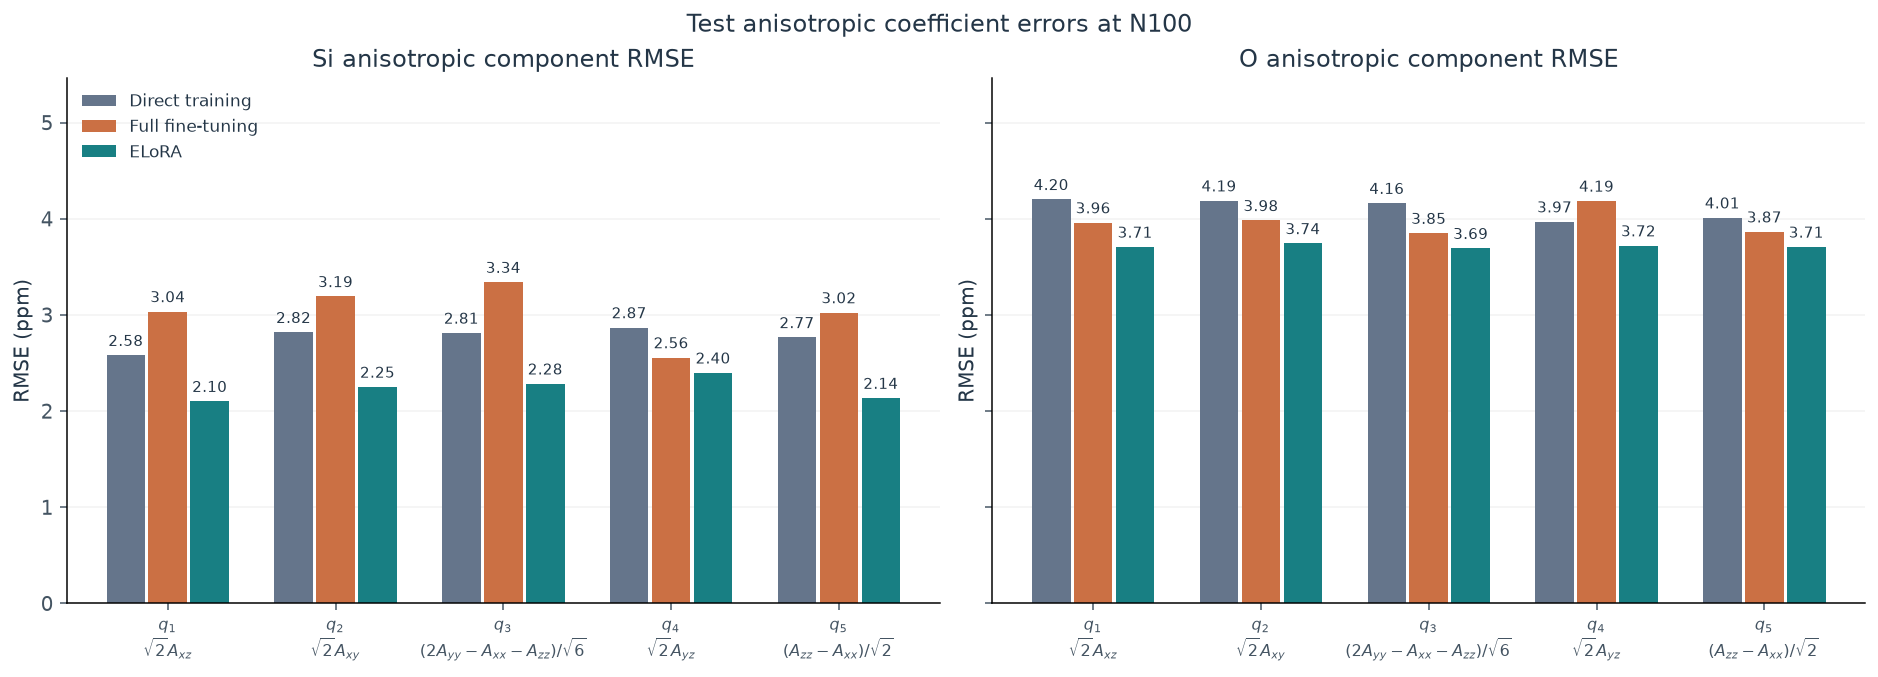

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


In [2]:
selected = components[components.Split == SPLIT]
display(selected.pivot(index=['Element', 'Component'], columns='Method', values='RMSE_ppm'))
fig = plot_component_rmse(components, SPLIT)
save_figure(fig, FIGURES, SPLIT + '-coefficient-rmse')
plt.show()


## Cartesian anisotropic tensor errors

Each 3×3 panel shows the RMSE of the corresponding Axx, Axy, …, Azz entry, with a shared colour scale across all methods and both elements. The signed predicted/reference coefficient vectors are converted into traceless Cartesian matrices before calculating the errors. No isotropic shielding error is included.

The matrix is symmetric, so off-diagonal cells appear twice; its diagonal entries are constrained by zero trace. Cartesian entries have different normalisations from the q coefficients, so their numerical RMSEs need not match the bars above. Different axis errors on a finite test set do not establish a failure of rotational equivariance.

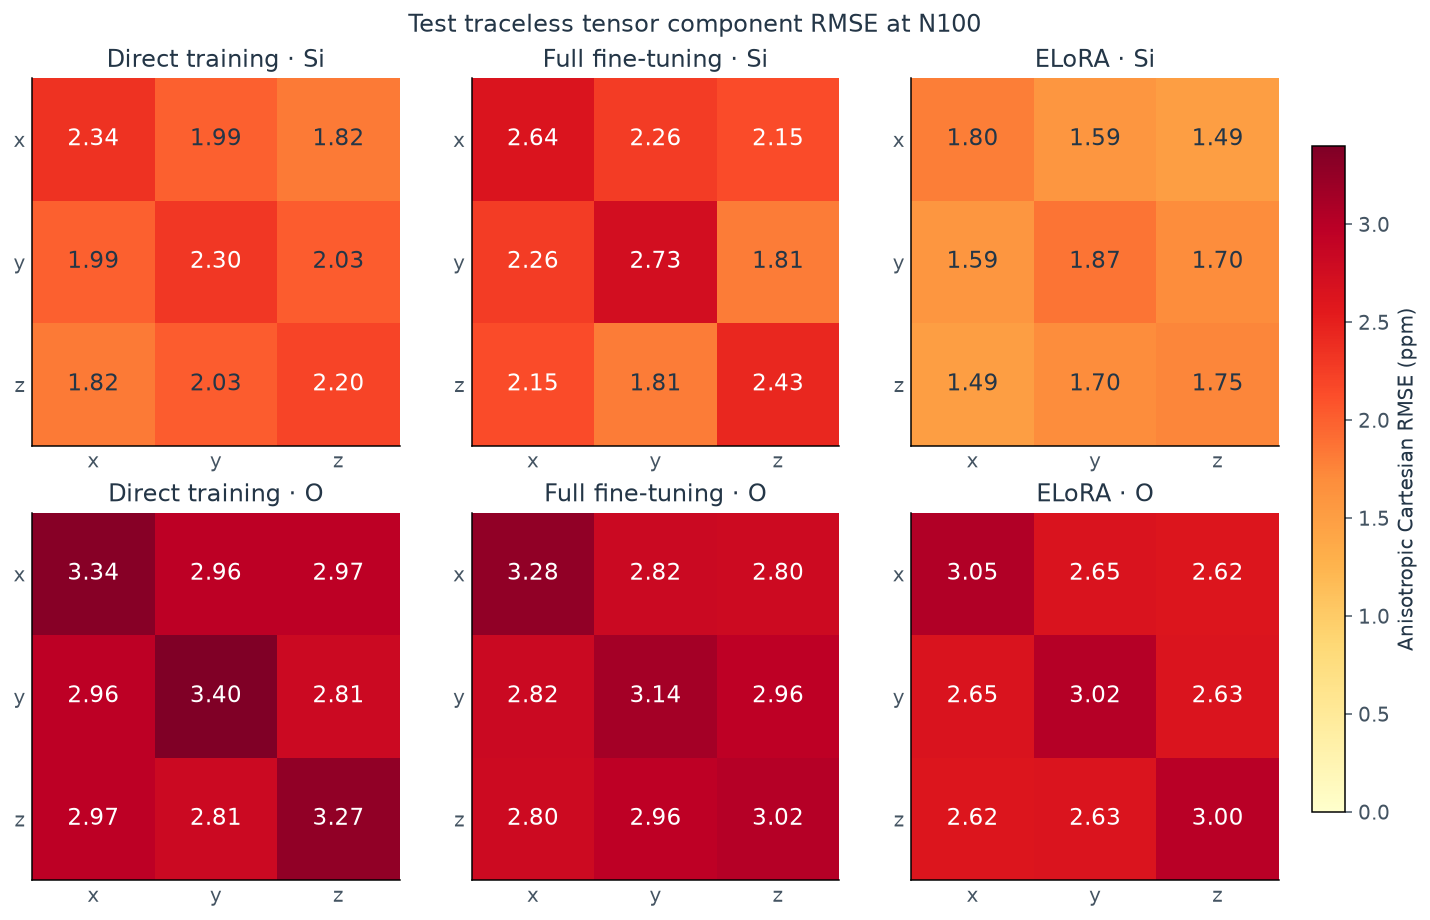

In [3]:
fig = plot_cartesian_rmse(cartesian, SPLIT)
save_figure(fig, FIGURES, SPLIT + '-cartesian-rmse')
plt.show()


## Concentration of squared error

For each component, select the 1% of atom predictions with the largest squared errors and calculate their share of the total squared error. A high percentage means rare large errors have a strong influence on that component’s RMSE. The atoms are ranked separately for every element, method and coefficient. On the test set this selects 72 Si predictions or 144 O predictions per cell.

The percentage describes concentration of error; use the RMSE bars for its absolute magnitude. A model can have lower RMSE while a larger fraction of its error comes from its worst predictions.

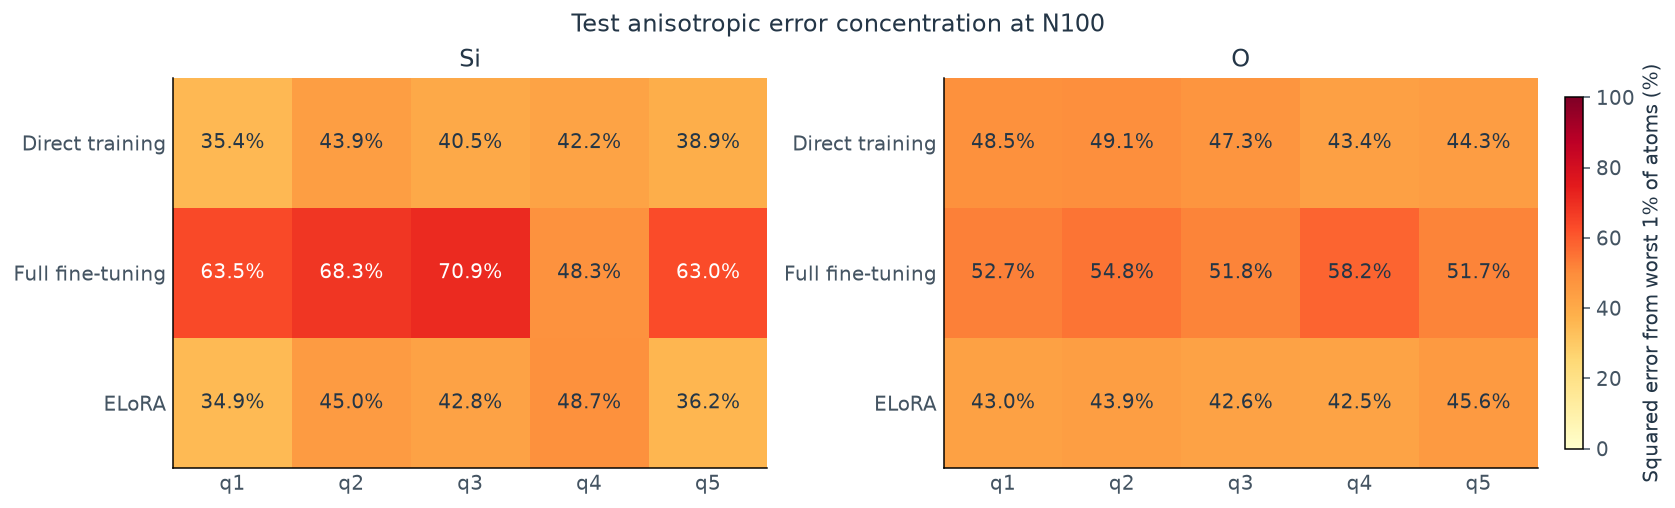

,Method,Element,Component,RMSE_ppm,MAE_ppm,Bias_ppm,P95_absolute_error_ppm,P99_absolute_error_ppm,Worst_1pct_MSE_share_percent
0,Direct training,Si,q1,2.581,1.622,0.013,4.700,10.267,35.360
1,Direct training,Si,q2,2.820,1.669,-0.005,4.828,10.941,43.931
2,Direct training,Si,q3,2.813,1.698,0.040,4.836,10.764,40.485
3,Direct training,Si,q4,2.869,1.695,-0.018,4.979,11.568,42.210
4,Direct training,Si,q5,2.766,1.684,0.040,4.850,11.096,38.890
5,Direct training,O,q1,4.202,2.400,-0.016,6.682,15.510,48.543
6,Direct training,O,q2,4.188,2.386,0.019,6.728,14.488,49.127
7,Direct training,O,q3,4.162,2.406,0.096,6.767,15.054,47.257
8,Direct training,O,q4,3.969,2.376,0.057,6.656,15.088,43.427
9,Direct training,O,q5,4.011,2.382,0.038,6.664,14.970,44.347


In [4]:
fig = plot_error_concentration(components, SPLIT)
save_figure(fig, FIGURES, SPLIT + '-error-concentration')
plt.show()
display(selected[['Method', 'Element', 'Component', 'RMSE_ppm', 'MAE_ppm', 'Bias_ppm',
                  'P95_absolute_error_ppm', 'P99_absolute_error_ppm', 'Worst_1pct_MSE_share_percent']].reset_index(drop=True))


## Findings

**ELoRA lowers test RMSE in all five coefficients for both Si and O relative to direct training.** Its improvement is spread across the complete tensor representation.

Full fine-tuning improves Si q₄ = √2 Ayz, but has higher error in the other four Si coefficients. Its largest Si component RMSE is q₃ = (2 Ayy − Axx − Azz)/√6: **3.340 ppm**, compared with **2.813 ppm** for direct training and **2.284 ppm** for ELoRA. For O, full fine-tuning improves four coefficients but worsens q₄.

For full fine-tuning’s Si q₃, the worst 1% of atom predictions account for **70.9%** of the squared error; the corresponding shares are **40.5%** for direct training and **42.8%** for ELoRA. The signed component biases are small (all test biases are below 0.10 ppm in magnitude), so a simple common component offset does not explain the larger errors. The outlier pattern is a reason to inspect the affected Si environments; it does not by itself identify their physical cause.

These component rankings refer to the stored DFT coordinate frame. The original pooled RMSEs and model choices are unchanged. The file [largest-component-errors.csv](symmetric-transfer-N100-data/anisotropic-components/largest-component-errors.csv) lists the ten largest errors in every method/element/component/split with zero-based frame and atom indices, so individual cases can be inspected.